In [1]:
#Assignment 2	Dimensioality Reduction : Implement Principal Component Analysis 			
#	https://www.datacamp.com/tutorial/principal-component-analysis-in-python			
#	https://www.geeksforgeeks.org/principal-component-analysis-with-python/			
#	https://builtin.com/machine-learning/pca-in-python

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Shape:", df.shape)

X = StandardScaler().fit_transform(df)

Shape: (569, 30)


Shape after PCA: (569, 2)
Variance explained: [0.44272026 0.18971182]
Total variance   : 0.6324320765155946


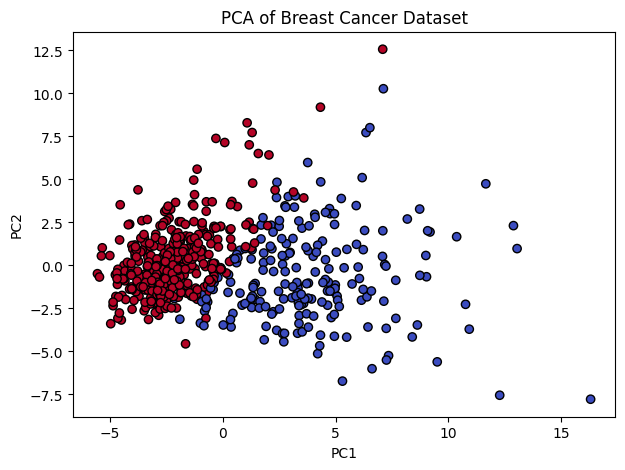

In [2]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print("Shape after PCA:", X_pca.shape)
print("Variance explained:", pca.explained_variance_ratio_)
print("Total variance   :", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', edgecolor='k')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of Breast Cancer Dataset')
plt.show()

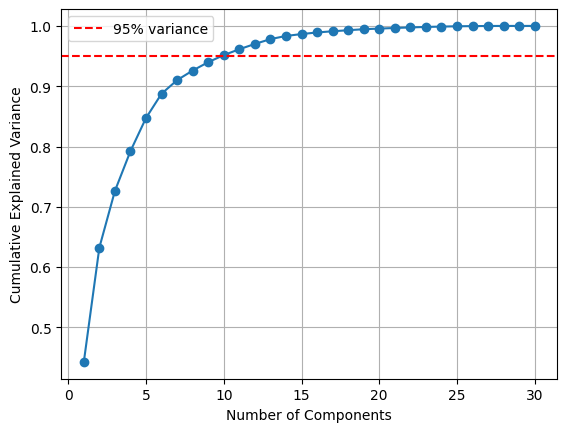

Components needed for 95% variance: 10


In [4]:
pca_full = PCA().fit(X)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.plot(range(1, 31), cum_var, marker='o')
plt.axhline(0.95, color='r', linestyle='--', label='95% variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

print("Components needed for 95% variance:", np.argmax(cum_var >= 0.95) + 1)